# 01 — EDA, Time-Ordered Split & Class Imbalance Analysis

**Project**: UPI Fraud Detection — Drift-Aware Explainable ML Framework
**Datasets**: IEEE-CIS Fraud Detection (primary), PaySim (secondary)
**Goal**: Understand data, create time-ordered splits, analyze class imbalance, prepare for baseline modeling

In [1]:
# Setup
import sys
from pathlib import Path

# Resolve the project root robustly (works whatever the kernel's cwd is)
_cwd = Path.cwd()
_project_root = None
for _c in [_cwd, *_cwd.parents]:
    if (_c / '.git').is_dir() or (_c / 'src' / 'data_prep.py').exists():
        _project_root = _c
        break
if _project_root is None:
    raise ImportError(f"Could not locate project root from cwd={_cwd}")

if str(_project_root / 'src') not in sys.path:
    sys.path.insert(0, str(_project_root / 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from data_prep import load_ieee_cis, load_paysim, time_ordered_split, prepare_features_target, handle_class_imbalance

# Display settings
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

DATA_ROOT = _project_root / 'data'
print(f"Project root: {_project_root}")
print(f"Data root: {DATA_ROOT}")


Project root: /Users/pavanc/Downloads/UPI_Fraud_Detection_Project
Data root: /Users/pavanc/Downloads/UPI_Fraud_Detection_Project/data


In [2]:
# Load IEEE-CIS
from IPython.display import display

try:
    ieee_df = load_ieee_cis(DATA_ROOT / 'ieee-cis')
    print(f"IEEE-CIS loaded: {ieee_df.shape}")
    print(f"Time range: {ieee_df['TransactionDT'].min()} to {ieee_df['TransactionDT'].max()}")
    print(f"Fraud rate: {ieee_df['isFraud'].mean():.4f}")
    display(ieee_df.head())  # type: ignore[unknown-name]
except FileNotFoundError as e:
    print(f"IEEE-CIS not found: {e}")
    ieee_df = None

IEEE-CIS loaded: (590540, 394)
Time range: 86400 to 15811131
Fraud rate: 0.0350


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,D13,D14,D15,M1,M2,M3,M4,...,V290,V291,V292,V293,V294,V295,V296,V297,V298,V299,V300,V301,V302,V303,V304,V305,V306,V307,V308,V309,V310,V311,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321,V322,V323,V324,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,1.0,1.0,14.0,NaN,13.0,NaN,NaN,NaN,NaN,NaN,NaN,13.0,13.0,NaN,NaN,NaN,0.0,T,T,T,M2,...,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,117.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,M0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,315.0,NaN,NaN,NaN,315.0,T,T,T,M0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN,2.0,5.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,1.0,0.0,25.0,1.0,112.0,112.0,0.0,94.0,0.0,NaN,NaN,NaN,NaN,84.0,NaN,NaN,NaN,NaN,111.0,NaN,NaN,NaN,M0,...,1.0,1.0,1.0,1.0,38.0,24.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,50.0,1758.0,925.0,0.0,354.0,0.0,135.0,0.0,0.0,0.0,50.0,1404.0,790.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
# Load PaySim
from IPython.display import display

try:
    paysim_df = load_paysim(DATA_ROOT / 'paysim')
    print(f"PaySim loaded: {paysim_df.shape}")
    print(f"Time range (steps): {paysim_df['step'].min()} to {paysim_df['step'].max()}")
    print(f"Fraud rate: {paysim_df['isFraud'].mean():.4f}")
    display(paysim_df.head())  # type: ignore[unknown-name]
except FileNotFoundError as e:
    print(f"PaySim not found: {e}")
    paysim_df = None

PaySim loaded: (6362620, 11)
Time range (steps): 1 to 743
Fraud rate: 0.0013


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.639648,C1231006815,170136.000000,160296.359375,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,5157.049805,C1562950869,1667.920044,0.000000,M2021835850,0.0,0.0,0,0
2,1,PAYMENT,5746.439941,C845388562,0.000000,0.000000,M550572371,0.0,0.0,0,0
3,1,PAYMENT,5607.359863,C948424584,5202.000000,0.000000,M1447685190,0.0,0.0,0,0
4,1,PAYMENT,6360.790039,C2027701910,3731.000000,0.000000,M1345293143,0.0,0.0,0,0


## 1. IEEE-CIS Exploratory Data Analysis

In [4]:
if ieee_df is not None:
    print("=== Shape ===", ieee_df.shape)
    print("=== dtypes ===")
    print(ieee_df.dtypes.value_counts())
    print("=== Missing values ===")
    missing = ieee_df.isnull().sum().sort_values(ascending=False)
    print(missing[missing > 0].head(20))
    print(f"Total missing: {missing.sum()}")
    print("=== Fraud distribution ===")
    print(ieee_df['isFraud'].value_counts())
    print(f"Fraud rate: {ieee_df['isFraud'].mean():.4%}")

=== Shape === (590540, 394)
=== dtypes ===
float64     368
str           9
float32       8
int64         2
int8          1
category      1
int32         1
category      1
category      1
category      1
category      1
Name: count, dtype: int64
=== Missing values ===
dist2    552913
D7       551623
D13      528588
D14      528353
D12      525823
D6       517353
D9       515614
D8       515614
V153     508595
V139     508595
V162     508595
V161     508595
V154     508595
V138     508595
V158     508595
V157     508595
V163     508595
V156     508595
V155     508595
V149     508595
dtype: int64
Total missing: 95566686
=== Fraud distribution ===
isFraud
0    569877
1     20663
Name: count, dtype: int64
Fraud rate: 3.4990%


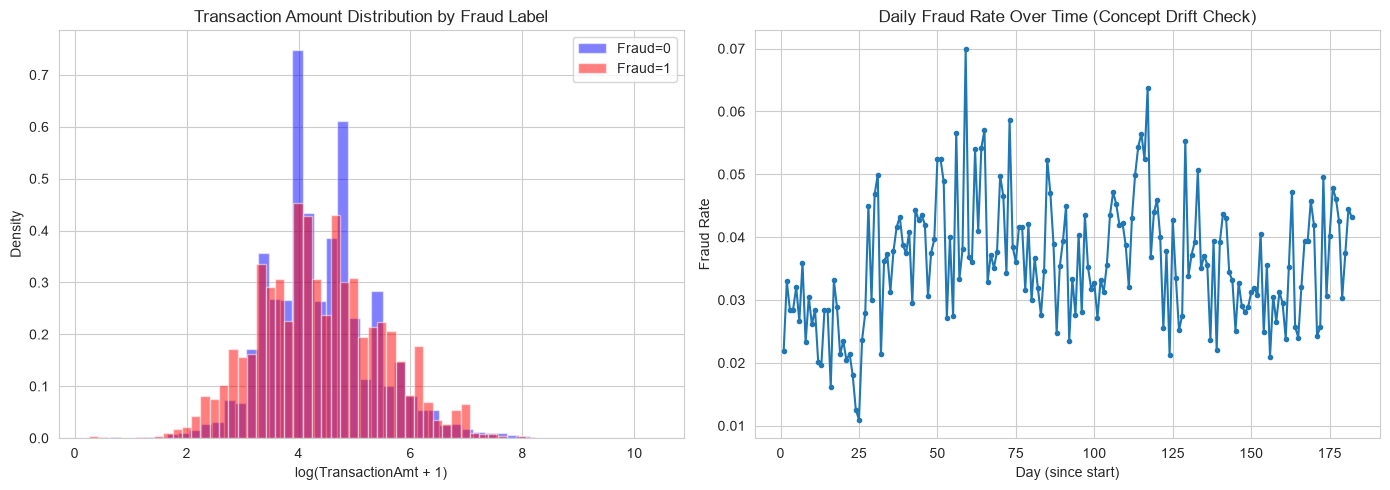

In [5]:
if ieee_df is not None:
    # Transaction amount by fraud
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Log amount distribution
    for label, color in [(0, 'blue'), (1, 'red')]:
        subset = ieee_df[ieee_df['isFraud'] == label]['TransactionAmt']
        axes[0].hist(np.log1p(subset), bins=50, alpha=0.5, label=f'Fraud={label}', color=color, density=True)
    axes[0].set_xlabel('log(TransactionAmt + 1)')
    axes[0].set_ylabel('Density')
    axes[0].set_title('Transaction Amount Distribution by Fraud Label')
    axes[0].legend()
    
    # Fraud rate over time (TransactionDT)
    ieee_df['day'] = (ieee_df['TransactionDT'] // 86400).astype(int)
    daily_fraud = ieee_df.groupby('day')['isFraud'].agg(['mean', 'count']).reset_index()
    daily_fraud.columns = ['day', 'fraud_rate', 'count']
    axes[1].plot(daily_fraud['day'], daily_fraud['fraud_rate'], marker='o', markersize=3)
    axes[1].set_xlabel('Day (since start)')
    axes[1].set_ylabel('Fraud Rate')
    axes[1].set_title('Daily Fraud Rate Over Time (Concept Drift Check)')
    
    plt.tight_layout()
    plt.show()

In [6]:
if ieee_df is not None:
    # Categorical feature fraud rates
    cat_cols = ieee_df.select_dtypes(include=['category']).columns.tolist()
    if 'isFraud' in cat_cols:
        cat_cols.remove('isFraud')
    
    print(f"Categorical columns ({len(cat_cols)}): {cat_cols[:10]}...")
    
    # Top categories by fraud rate for first few cat columns
    for col in cat_cols[:5]:
        fraud_by_cat = ieee_df.groupby(col)['isFraud'].agg(['mean', 'count']).reset_index()
        fraud_by_cat = fraud_by_cat[fraud_by_cat['count'] > 100].sort_values('mean', ascending=False)
        print(f"\n{col} - Top 10 by fraud rate:")
        print(fraud_by_cat.head(10).to_string(index=False))

Categorical columns (5): ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain']...

ProductCD - Top 10 by fraud rate:
ProductCD     mean  count
        C 0.116873  68519
        S 0.058996  11628
        H 0.047662  33024
        R 0.037826  37699
        W 0.020399 439670

card4 - Top 10 by fraud rate:
           card4     mean  count
        discover 0.077282   6651
            visa 0.034756 384767
      mastercard 0.034331 189217
american express 0.028698   8328

card6 - Top 10 by fraud rate:
 card6     mean  count
credit 0.066785 148986
 debit 0.024263 439938

P_emaildomain - Top 10 by fraud rate:
 P_emaildomain     mean  count
      mail.com 0.189624    559
    outlook.es 0.130137    438
       aim.com 0.126984    315
   outlook.com 0.094584   5096
    hotmail.es 0.065574    305
   live.com.mx 0.054740    749
   hotmail.com 0.052950  45250
     gmail.com 0.043542 228355
      yahoo.fr 0.034965    143
embarqmail.com 0.034615    260

R_emaildomain - Top 10 by fraud rate:


Top 15 numerical features correlated with fraud:
isFraud    1.000000
V257       0.383060
V246       0.366878
V244       0.364129
V242       0.360590
V201       0.328005
V200       0.318783
V189       0.308219
V188       0.303582
V258       0.297151
V45        0.281832
V158       0.278066
V156       0.275952
V149       0.273282
V228       0.268861
Name: isFraud, dtype: float64


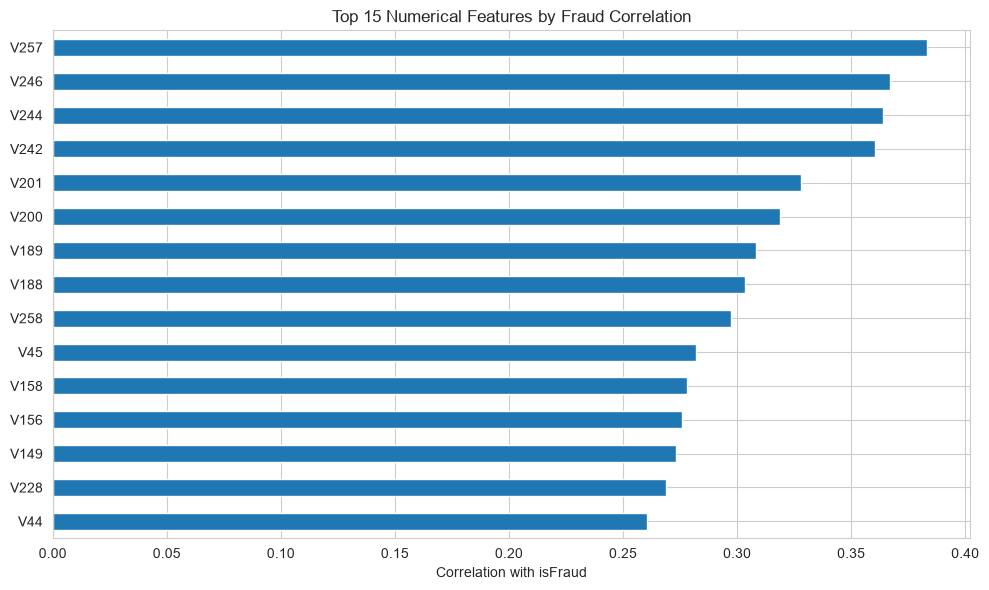

In [7]:
if ieee_df is not None:
    # Numerical feature correlations with fraud
    num_cols = ieee_df.select_dtypes(include=[np.number]).columns.tolist()
    num_cols = [c for c in num_cols if c not in ['TransactionID', 'TransactionDT', 'isFraud', 'day']]
    
    correlations = ieee_df[num_cols + ['isFraud']].corr()['isFraud'].sort_values(ascending=False)
    print("Top 15 numerical features correlated with fraud:")
    print(correlations.head(15))
    
    # Plot top correlations
    top_corr = correlations[1:16]  # exclude isFraud itself
    plt.figure(figsize=(10, 6))
    top_corr.plot(kind='barh')
    plt.xlabel('Correlation with isFraud')
    plt.title('Top 15 Numerical Features by Fraud Correlation')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

## 2. PaySim Exploratory Data Analysis

In [8]:
if paysim_df is not None:
    print("=== Shape ===", paysim_df.shape)
    print("=== dtypes ===")
    print(paysim_df.dtypes.value_counts())
    print("=== Missing values ===")
    missing = paysim_df.isnull().sum()
    print(missing[missing > 0])
    print("=== Fraud distribution ===")
    print(paysim_df['isFraud'].value_counts())
    print(f"Fraud rate: {paysim_df['isFraud'].mean():.4%}")
    print("=== Transaction types ===")
    print(paysim_df['type'].value_counts())

=== Shape === (6362620, 11)
=== dtypes ===


float32     5
int8        2
int32       1
category    1
category    1
category    1
Name: count, dtype: int64
=== Missing values ===
Series([], dtype: int64)
=== Fraud distribution ===
isFraud
0    6354407
1       8213
Name: count, dtype: int64
Fraud rate: 0.1291%
=== Transaction types ===
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


    type  fraud_rate   count
 CASH_IN    0.000000 1399284
CASH_OUT    0.001840 2237500
   DEBIT    0.000000   41432
 PAYMENT    0.000000 2151495
TRANSFER    0.007688  532909


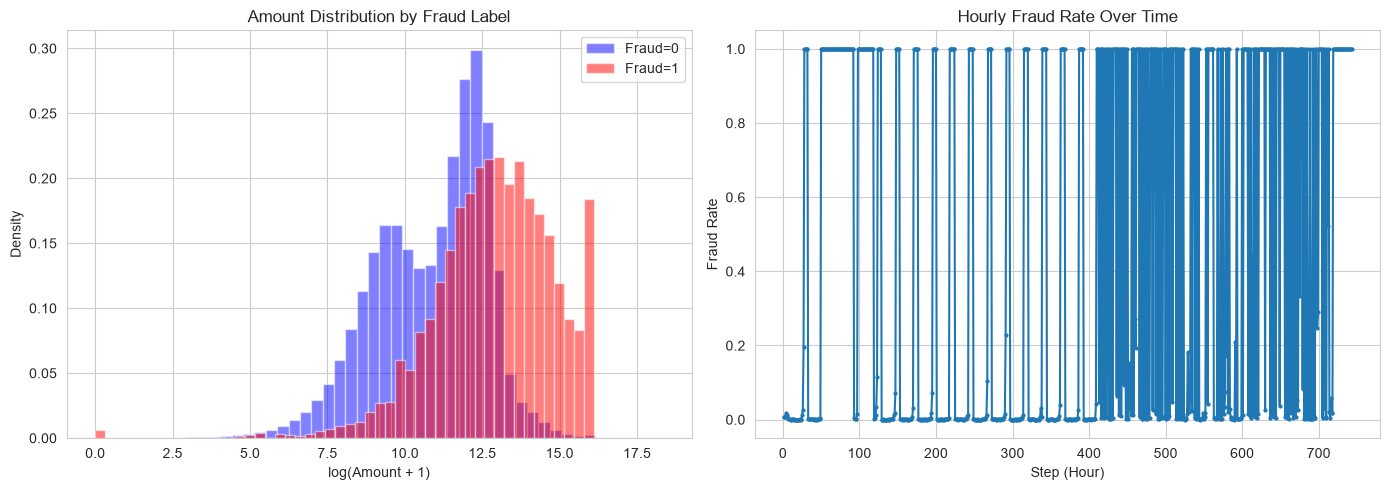

In [9]:
if paysim_df is not None:
    # Fraud by transaction type
    fraud_by_type = paysim_df.groupby('type')['isFraud'].agg(['mean', 'count']).reset_index()
    fraud_by_type.columns = ['type', 'fraud_rate', 'count']
    print(fraud_by_type.to_string(index=False))
    
    # Amount distribution by fraud
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for label, color in [(0, 'blue'), (1, 'red')]:
        subset = paysim_df[paysim_df['isFraud'] == label]['amount']
        axes[0].hist(np.log1p(subset), bins=50, alpha=0.5, label=f'Fraud={label}', color=color, density=True)
    axes[0].set_xlabel('log(Amount + 1)')
    axes[0].set_ylabel('Density')
    axes[0].set_title('Amount Distribution by Fraud Label')
    axes[0].legend()
    
    # Fraud rate over steps (time)
    step_fraud = paysim_df.groupby('step')['isFraud'].agg(['mean', 'count']).reset_index()
    step_fraud.columns = ['step', 'fraud_rate', 'count']
    axes[1].plot(step_fraud['step'], step_fraud['fraud_rate'], marker='o', markersize=2)
    axes[1].set_xlabel('Step (Hour)')
    axes[1].set_ylabel('Fraud Rate')
    axes[1].set_title('Hourly Fraud Rate Over Time')
    
    plt.tight_layout()
    plt.show()

## 3. Time-Ordered Train/Val/Test Split

In [10]:
# Split IEEE-CIS
if ieee_df is not None:
    print("=== IEEE-CIS Time-Ordered Split (70/15/15) ===")
    train_ieee, val_ieee, test_ieee = time_ordered_split(ieee_df, 'TransactionDT')
    
    # Save splits
    split_dir = DATA_ROOT / 'ieee-cis' / 'splits'
    split_dir.mkdir(parents=True, exist_ok=True)
    train_ieee.to_parquet(split_dir / 'train.parquet', index=False)
    val_ieee.to_parquet(split_dir / 'val.parquet', index=False)
    test_ieee.to_parquet(split_dir / 'test.parquet', index=False)
    print(f"Splits saved to {split_dir}")

=== IEEE-CIS Time-Ordered Split (70/15/15) ===
  train: 413,378 rows (70.0%), fraud_rate=0.03516878014795175
  val: 88,581 rows (15.0%), fraud_rate=0.03434145019812375
  test: 88,581 rows (15.0%), fraud_rate=0.03480430340592226


Splits saved to /Users/pavanc/Downloads/UPI_Fraud_Detection_Project/data/ieee-cis/splits


In [11]:
# Split PaySim
if paysim_df is not None:
    print("=== PaySim Time-Ordered Split (70/15/15) ===")
    train_paysim, val_paysim, test_paysim = time_ordered_split(paysim_df, 'step')
    
    split_dir = DATA_ROOT / 'paysim' / 'splits'
    split_dir.mkdir(parents=True, exist_ok=True)
    train_paysim.to_parquet(split_dir / 'train.parquet', index=False)
    val_paysim.to_parquet(split_dir / 'val.parquet', index=False)
    test_paysim.to_parquet(split_dir / 'test.parquet', index=False)
    print(f"Splits saved to {split_dir}")

=== PaySim Time-Ordered Split (70/15/15) ===
  train: 4,453,834 rows (70.0%), fraud_rate=0.0008170488617222824
  val: 954,393 rows (15.0%), fraud_rate=0.000590951526258051
  test: 954,393 rows (15.0%), fraud_rate=0.004201623440238979


Splits saved to /Users/pavanc/Downloads/UPI_Fraud_Detection_Project/data/paysim/splits


## 4. Class Imbalance Analysis & Handling Strategy

In [12]:
def analyze_imbalance(y, name):
    """Analyze class imbalance and recommend handling."""
    fraud_rate = y.mean()
    n_fraud = y.sum()
    n_normal = len(y) - n_fraud
    ratio = n_normal / n_fraud if n_fraud > 0 else np.inf
    
    print(f"=== {name} Class Imbalance ===")
    print(f"  Total: {len(y):,}")
    print(f"  Fraud: {n_fraud:,} ({fraud_rate:.4%})")
    print(f"  Normal: {n_normal:,} ({1-fraud_rate:.4%})")
    print(f"  Imbalance ratio (normal:fraud): {ratio:.1f}:1")
    
    # Recommendations
    if ratio > 100:
        print(f"  → EXTREME imbalance: Use class_weight + consider SMOTE/ADASYN")
    elif ratio > 20:
        print(f"  → HIGH imbalance: Use class_weight (scale_pos_weight={ratio:.1f})")
    elif ratio > 5:
        print(f"  → MODERATE imbalance: class_weight recommended")
    else:
        print(f"  → Low imbalance: Standard training OK")
    
    return fraud_rate, ratio

if ieee_df is not None:
    X_train, y_train = prepare_features_target(train_ieee)
    analyze_imbalance(y_train, "IEEE-CIS Train")
    
    # Get class_weight params
    params = handle_class_imbalance(X_train, y_train, method='class_weight')
    print(f"\nRecommended XGBoost/LightGBM params: {params}")

=== IEEE-CIS Train Class Imbalance ===
  Total: 413,378
  Fraud: 14,538 (3.5169%)
  Normal: 398,840 (96.4831%)
  Imbalance ratio (normal:fraud): 27.4:1
  → HIGH imbalance: Use class_weight (scale_pos_weight=27.4)

Recommended XGBoost/LightGBM params: {'scale_pos_weight': np.float64(27.43431008391801), 'class_weight': 'balanced'}


In [13]:
if paysim_df is not None:
    X_train_p, y_train_p = prepare_features_target(train_paysim)
    analyze_imbalance(y_train_p, "PaySim Train")
    
    params_p = handle_class_imbalance(X_train_p, y_train_p, method='class_weight')
    print(f"\nRecommended XGBoost/LightGBM params: {params_p}")

=== PaySim Train Class Imbalance ===
  Total: 4,453,834
  Fraud: 3,639 (0.0817%)
  Normal: 4,450,195 (99.9183%)
  Imbalance ratio (normal:fraud): 1222.9:1
  → EXTREME imbalance: Use class_weight + consider SMOTE/ADASYN

Recommended XGBoost/LightGBM params: {'scale_pos_weight': np.float64(1222.9170101676284), 'class_weight': 'balanced'}


## 5. Feature Engineering Preview

In [14]:
def basic_feature_engineering(df, dataset_name):
    """Apply basic feature engineering."""
    df = df.copy()
    
    if dataset_name == 'ieee-cis':
        # Time features from TransactionDT (seconds since epoch)
        df['hour'] = (df['TransactionDT'] // 3600) % 24
        df['day_of_week'] = (df['TransactionDT'] // 86400) % 7
        
        # Amount features
        df['amount_log'] = np.log1p(df['TransactionAmt'])
        df['amount_round'] = (df['TransactionAmt'] == df['TransactionAmt'].round()).astype(int)
        
        # Card features
        if 'card1' in df.columns:
            df['card1_freq'] = df.groupby('card1')['card1'].transform('count')
    
    elif dataset_name == 'paysim':
        # Time features from step (hours)
        df['hour'] = df['step'] % 24
        df['day'] = df['step'] // 24
        
        # Amount features
        df['amount_log'] = np.log1p(df['amount'])
        df['amount_round'] = (df['amount'] == df['amount'].round()).astype(int)
        
        # Balance change features
        df['orig_balance_diff'] = df['oldbalanceOrg'] - df['newbalanceOrig']
        df['dest_balance_diff'] = df['newbalanceDest'] - df['oldbalanceDest']
        df['zero_balance_orig'] = (df['oldbalanceOrg'] == 0).astype(int)
        df['zero_balance_dest'] = (df['oldbalanceDest'] == 0).astype(int)
    
    return df

if ieee_df is not None:
    train_ieee_fe = basic_feature_engineering(train_ieee, 'ieee-cis')
    print(f"Engineered features: {train_ieee_fe.shape[1] - train_ieee.shape[1]} new columns")
    print(f"New columns: {[c for c in train_ieee_fe.columns if c not in train_ieee.columns]}")

Engineered features: 5 new columns
New columns: ['hour', 'day_of_week', 'amount_log', 'amount_round', 'card1_freq']


In [15]:
if paysim_df is not None:
    train_paysim_fe = basic_feature_engineering(train_paysim, 'paysim')
    print(f"Engineered features: {train_paysim_fe.shape[1] - train_paysim.shape[1]} new columns")
    print(f"New columns: {[c for c in train_paysim_fe.columns if c not in train_paysim.columns]}")

Engineered features: 8 new columns
New columns: ['hour', 'day', 'amount_log', 'amount_round', 'orig_balance_diff', 'dest_balance_diff', 'zero_balance_orig', 'zero_balance_dest']


## 6. Summary & Next Steps

In [16]:
print("""
=== EDA SUMMARY ===

✅ Data loaded and validated
✅ Time-ordered splits created (70/15/15)
✅ Class imbalance analyzed
✅ Basic feature engineering applied

NEXT: Notebook 02_baselines.ipynb
- Train Logistic Regression, Random Forest, XGBoost, LightGBM
- Rolling time-window cross-validation
- Evaluate: PR-AUC, Precision@K, Recall@K
- Log results for comparison
""")


=== EDA SUMMARY ===

✅ Data loaded and validated
✅ Time-ordered splits created (70/15/15)
✅ Class imbalance analyzed
✅ Basic feature engineering applied

NEXT: Notebook 02_baselines.ipynb
- Train Logistic Regression, Random Forest, XGBoost, LightGBM
- Rolling time-window cross-validation
- Evaluate: PR-AUC, Precision@K, Recall@K
- Log results for comparison

